# Statistical Analysis: Daylight Saving Time and Fatal Crashes

This notebook is for our statistical analysis of whether Daylight Saving Time (DST)
transitions are associated with changes in fatal traffic crashes in the United States.

It uses the combined FARS dataset (2000-2024) created in `00_data_preparation.ipynb`.
Each row is one fatal crash, not one fatality.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Loading the combined FARS dataset
fars = pd.read_parquet("../data/fars_2000_2024.parquet")

print("Rows:", len(fars))
print("Columns:", fars.shape[1])


Rows: 881056
Columns: 104


In [3]:

# Making a copy for our DST analysis
dst_crashes = fars.copy()

# Checking that we have the columns we need
print(dst_crashes[["year", "month", "day", "state"]].head())

# Checking for invalid crash dates
dst_crashes["crash_date"] = pd.to_datetime(
    dst_crashes[["year", "month", "day"]],
    errors="coerce"
)

print("\nMissing or invalid dates:",
      dst_crashes["crash_date"].isna().sum())

# Checking which states are included
print("\nNumber of state codes:",
      dst_crashes["state"].nunique())


   year  month  day  state
0  2000      1    1      1
1  2000      1    3      1
2  2000      1    9      1
3  2000      1    6      1
4  2000      1    4      1

Missing or invalid dates: 78

Number of state codes: 51


In [4]:

import calendar
from datetime import date

# Finding the DST transition dates from 2000 to 2024
dst_dates = []

for year in range(2000, 2025):

    if year < 2007:
        spring_month = 4
        fall_month = 10
    else:
        spring_month = 3
        fall_month = 11

    # Finding the Sundays in each month
    spring_sundays = [
        week[calendar.SUNDAY]
        for week in calendar.monthcalendar(year, spring_month)
        if week[calendar.SUNDAY] != 0
    ]

    fall_sundays = [
        week[calendar.SUNDAY]
        for week in calendar.monthcalendar(year, fall_month)
        if week[calendar.SUNDAY] != 0
    ]

    if year < 2007:
        spring_day = spring_sundays[0]
        fall_day = fall_sundays[-1]
    else:
        spring_day = spring_sundays[1]
        fall_day = fall_sundays[0]

    dst_dates.append({
        "year": year,
        "spring_dst": date(year, spring_month, spring_day),
        "fall_dst": date(year, fall_month, fall_day)
    })

# Converting to a DataFrame
dst_dates = pd.DataFrame(dst_dates)

display(dst_dates.head())


,year,spring_dst,fall_dst
0,2000,2000-04-02,2000-10-29
1,2001,2001-04-01,2001-10-28
2,2002,2002-04-07,2002-10-27
3,2003,2003-04-06,2003-10-26
4,2004,2004-04-04,2004-10-31


In [5]:

# Keeping crashes from states with consistent DST observance
dst_crashes = dst_crashes[
    ~dst_crashes["state"].isin([4, 15, 18, 72])
].copy()

# Matching each crash with its year's DST transition
dst_crashes = dst_crashes.merge(
    dst_dates[["year", "spring_dst"]],
    on="year",
    how="left"
)

# Converting the DST dates to datetime
dst_crashes["spring_dst"] = pd.to_datetime(
    dst_crashes["spring_dst"]
)

# Calculating days before or after spring DST
dst_crashes["days_from_spring"] = (
    dst_crashes["crash_date"] - dst_crashes["spring_dst"]
).dt.days

# Keeping crashes within two weeks of the transition
spring_crashes = dst_crashes[
    dst_crashes["days_from_spring"].between(-14, 14)
].copy()

print("Crashes included:", len(spring_crashes))
print("Years covered:", spring_crashes["year"].nunique())

display(
    spring_crashes[
        ["year", "crash_date", "spring_dst", "days_from_spring"]
    ].head()
)


Crashes included: 60347
Years covered: 25


,year,crash_date,spring_dst,days_from_spring
159,2000,2000-03-25,2000-04-02,-8.0
161,2000,2000-03-24,2000-04-02,-9.0
163,2000,2000-03-19,2000-04-02,-14.0
164,2000,2000-03-22,2000-04-02,-11.0
165,2000,2000-03-23,2000-04-02,-10.0


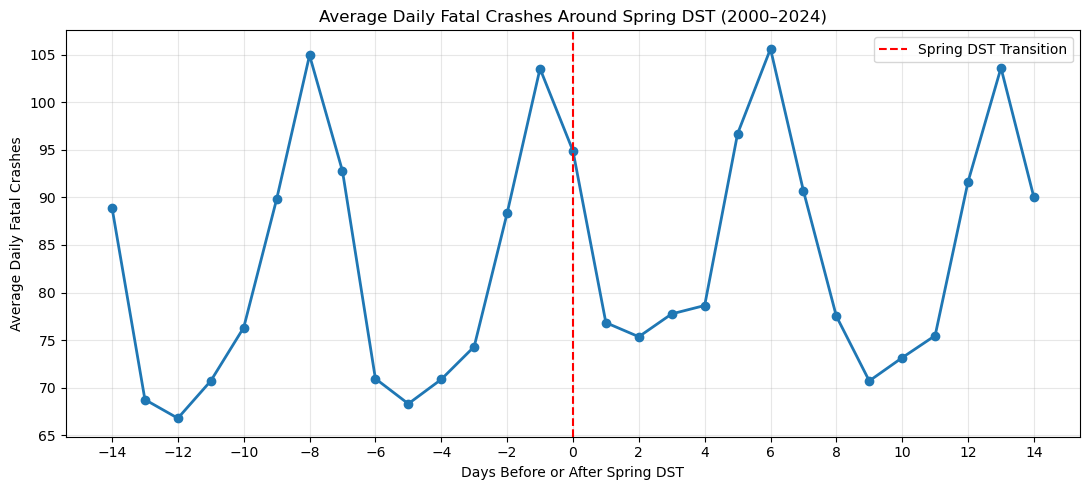

In [6]:

# Counting crashes for each day around spring DST
spring_daily = (
    spring_crashes.groupby(["year", "days_from_spring"])
    .size()
    .reset_index(name="crashes")
)

# Averaging the daily counts across years
spring_avg = (
    spring_daily.groupby("days_from_spring")["crashes"]
    .mean()
    .reset_index()
)

# Plotting crashes around the spring transition
plt.figure(figsize=(11, 5))

plt.plot(
    spring_avg["days_from_spring"],
    spring_avg["crashes"],
    marker="o",
    linewidth=2
)

plt.axvline(0, color="red", linestyle="--",
            label="Spring DST Transition")

plt.title("Average Daily Fatal Crashes Around Spring DST (2000–2024)")
plt.xlabel("Days Before or After Spring DST")
plt.ylabel("Average Daily Fatal Crashes")
plt.xticks(range(-14, 15, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Comparing Fatal Crashes Before and After Spring DST

Our initial graph shows a clear weekly pattern in fatal crashes, with higher crash counts on weekends and lower counts during weekdays. This makes a direct comparison of consecutive days around the DST transition potentially misleading.

To account for this, we compare the six days from Monday through Saturday before the spring transition (days -6 to -1) with the same six weekdays after the transition (days +1 to +6).

We calculate the average number of fatal crashes per day in each period and the percentage change following DST.

This provides an initial descriptive comparison of crash frequencies before and after DST. However, it does not establish causation, since other factors such as seasonal trends, weather, and traffic volume may also influence crash counts.


In [7]:

# Comparing Monday to Saturday before and after spring DST
before = spring_crashes[
    spring_crashes["days_from_spring"].between(-6, -1)
]

after = spring_crashes[
    spring_crashes["days_from_spring"].between(1, 6)
]

# Calculating average crashes per day across the 25 years
before_avg = len(before) / (25 * 6)
after_avg = len(after) / (25 * 6)

# Calculating the percentage change
percent_change = ((after_avg - before_avg) / before_avg) * 100

print(f"Before DST: {before_avg:.2f} crashes per day")
print(f"After DST: {after_avg:.2f} crashes per day")
print(f"Percentage change: {percent_change:.2f}%")


Before DST: 79.39 crashes per day
After DST: 85.15 crashes per day
Percentage change: 7.26%



### Preliminary Findings: Spring DST Transition

Using fatal crash records from 2000 to 2024, we compared average daily crash counts during the six weekdays (Monday–Saturday) before and after the spring DST transition.

The average increased from 79.39 crashes per day before the transition to 85.15 crashes per day afterward, representing a 7.26% increase.

This preliminary finding suggests a positive association between the spring DST transition and fatal crash frequency. However, this comparison does not account for seasonal trends, weather, traffic exposure, or other potential confounding factors.

Further statistical analysis is needed to determine whether this difference is statistically significant and whether it persists after accounting for these factors.



### Paired T-Test: Fatal Crashes Before and After Spring DST

Our descriptive analysis found a 7.26% increase in average daily fatal crashes during the six days following the spring DST transition.

We now test whether this difference is statistically significant.

For each year from 2000 to 2024, we calculate the average daily fatal crashes during Monday through Saturday before and after the transition.

Because both observations come from the same year, we use a paired t-test to compare the two periods.

**Null Hypothesis (H0):** There is no difference in the mean daily fatal crash count before and after spring DST.

**Alternative Hypothesis (H1):** The mean daily fatal crash count is higher after the spring DST transition.

We use a significance level of 0.05.


In [8]:

# Calculating average daily crashes before DST for each year
before_yearly = (
    before.groupby("year")
    .size()
    .div(6)
)

# Calculating average daily crashes after DST for each year
after_yearly = (
    after.groupby("year")
    .size()
    .div(6)
)

# Combining the yearly averages
paired_data = pd.DataFrame({
    "before": before_yearly,
    "after": after_yearly
})

# Calculating the difference for each year
paired_data["difference"] = (
    paired_data["after"] - paired_data["before"]
)

display(paired_data)


,before,after,difference
year,,,
2000,82.000000,96.666667,14.666667
2001,83.000000,86.333333,3.333333
2002,90.500000,87.833333,-2.666667
2003,94.666667,98.166667,3.500000
2004,90.500000,99.833333,9.333333
2005,91.500000,105.000000,13.500000
2006,90.333333,94.666667,4.333333
2007,94.500000,99.666667,5.166667
2008,74.000000,72.666667,-1.333333


In [9]:

from scipy import stats

# Running a paired t-test
t_stat, p_value = stats.ttest_rel(
    paired_data["after"],
    paired_data["before"],
    alternative="greater"
)

# Calculating a 95% confidence interval for the mean difference
mean_diff = paired_data["difference"].mean()
std_error = stats.sem(paired_data["difference"])

ci = stats.t.interval(
    confidence=0.95,
    df=len(paired_data) - 1,
    loc=mean_diff,
    scale=std_error
)

print(f"Mean difference: {mean_diff:.2f} crashes per day")
print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_value:.4f}")
print(f"95% CI for mean difference: ({ci[0]:.2f}, {ci[1]:.2f})")


Mean difference: 5.76 crashes per day
T-statistic: 4.408
P-value: 0.0001
95% CI for mean difference: (3.06, 8.46)



### Preliminary Findings: Paired T-Test

The paired t-test found a statistically significant increase in fatal traffic crashes following the spring DST transition (t = 4.408, p = 0.0001).

Across the 25 years analyzed, the mean difference was 5.76 additional fatal crashes per day, corresponding to a 7.26% increase from the pre-transition average. The 95% confidence interval for the mean difference was 3.06 to 8.46 crashes per day.

These results provide evidence that fatal crash counts are higher during the six days following the spring DST transition compared with the six preceding days.

However, this remains an observational comparison. Additional modeling is necessary to determine whether the association persists after accounting for seasonal trends and other potential confounding factors.



### Year-by-Year Differences in Fatal Crashes

To understand whether the observed increase is consistent across the study period, we examine the difference in average daily fatal crashes before and after the spring DST transition for each year.

Positive values indicate more crashes after the transition, while negative values indicate fewer crashes.


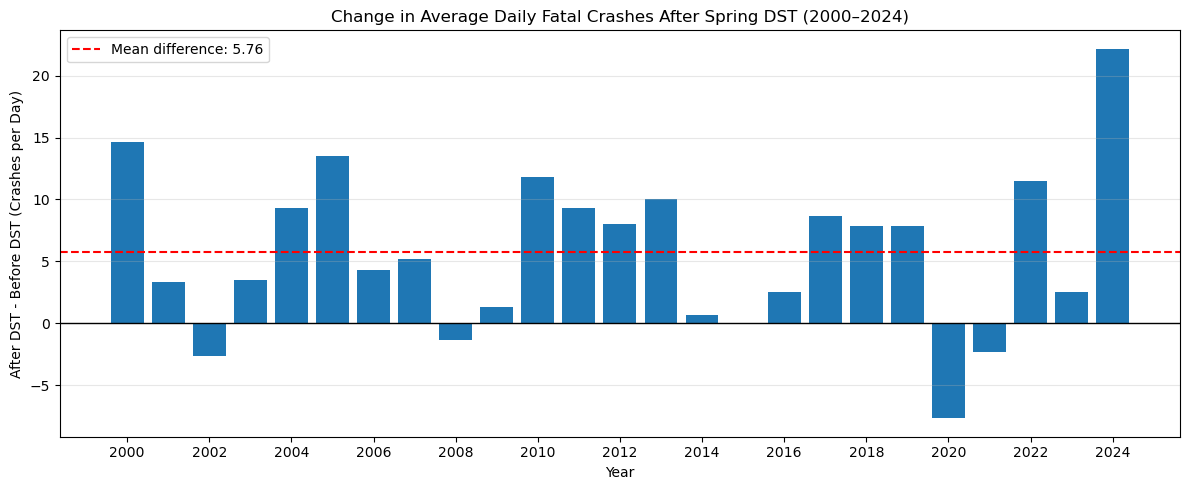

In [10]:

# Plotting the difference in crashes for each year
plt.figure(figsize=(12, 5))

plt.bar(
    paired_data.index,
    paired_data["difference"]
)

plt.axhline(0, color="black", linewidth=1)
plt.axhline(mean_diff, color="red", linestyle="--",
            label=f"Mean difference: {mean_diff:.2f}")

plt.title("Change in Average Daily Fatal Crashes After Spring DST (2000–2024)")
plt.xlabel("Year")
plt.ylabel("After DST - Before DST (Crashes per Day)")
plt.xticks(range(2000, 2025, 2))
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Preliminary Findings: Year-by-Year Differences

The year-by-year comparison shows that fatal crash counts increased following the spring DST transition in most years between 2000 and 2024.

Of the 25 years analyzed, 20 showed positive differences, while four showed negative differences and one showed approximately no change.

The average increase was 5.76 fatal crashes per day, although the magnitude varied considerably across years. The largest positive difference occurred in 2024, while 2020 showed the largest decrease.

These findings suggest that the observed increase is relatively consistent across years rather than being driven by only a few observations.

However, the variation between years indicates that other factors, including seasonal changes and fluctuations in traffic activity, may also influence crash frequencies.


In [11]:

# Comparing fatal crashes in Arizona and New Mexico
state_data = fars[fars["state"].isin([4, 35])].copy()

# Adding state names
state_data["state_name"] = state_data["state"].map({
    4: "Arizona",
    35: "New Mexico"
})

# Checking yearly crash counts
state_yearly = (
    state_data.groupby(["year", "state_name"])
    .size()
    .unstack()
)

display(state_yearly)

# Checking total crashes
print("\nTotal crashes by state:")
print(state_data["state_name"].value_counts())


state_name,Arizona,New Mexico
year,,
2000,891,386
2001,938,415
2002,984,398
2003,973,367
2004,990,439
2005,1038,420
2006,1118,424
2007,952,371
2008,843,324



Total crashes by state:
state_name
Arizona       23082
New Mexico     9125
Name: count, dtype: int64



## Control Group Analysis: Arizona and Hawaii

### Research Objective

Our initial analysis found a 7.26% increase in average daily fatal crashes following the spring DST transition across DST-observing states.

However, this increase could be influenced by seasonal changes, weather conditions, or other factors unrelated to the clock change.

To investigate this further, we examine Arizona and Hawaii, two states that generally do not observe Daylight Saving Time.

### Why Arizona and Hawaii?

Arizona and Hawaii provide useful comparison groups because most residents do not change their clocks during the spring transition.

We will examine fatal crash counts in these states around the same dates when DST begins elsewhere in the United States.

If similar increases occur in Arizona and Hawaii, this could suggest that seasonal changes contribute to the increase observed in DST-observing states.

If the increases are smaller or absent, this would motivate further investigation into whether the clock change itself contributes to crash risk.

### Methodology

We use FARS fatal crash data from 2000 to 2024.

For each state, we compare:

- Before: Monday through Saturday (days -6 to -1).
- After: Monday through Saturday (days +1 to +6).

We exclude the transition Sunday to maintain consistency with our earlier analysis.

We calculate the average daily fatal crash count and the percentage change for each state.

### Limitations

Arizona and Hawaii differ substantially in climate, geography, population, and traffic patterns. Additionally, the Navajo Nation in Arizona observes DST.

Therefore, these comparisons are exploratory and cannot independently establish a causal effect of DST.


In [12]:

# Comparing fatal crashes in Arizona and Hawaii
state_data = fars[fars["state"].isin([4, 15])].copy()

# Adding state names
state_data["state_name"] = state_data["state"].map({
    4: "Arizona",
    15: "Hawaii"
})

# Checking yearly crash counts
state_yearly = (
    state_data.groupby(["year", "state_name"])
    .size()
    .unstack()
)

display(state_yearly)

# Checking total crashes
print("\nTotal crashes by state:")
print(state_data["state_name"].value_counts())


state_name,Arizona,Hawaii
year,,
2000,891,116
2001,938,132
2002,984,115
2003,973,115
2004,990,128
2005,1038,129
2006,1118,144
2007,952,125
2008,843,102



Total crashes by state:
state_name
Arizona    23082
Hawaii      2685
Name: count, dtype: int64


In [13]:

# Creating crash dates
state_data["crash_date"] = pd.to_datetime(
    state_data[["year", "month", "day"]],
    errors="coerce"
)

# Adding the spring DST date for each year
state_data = state_data.merge(
    dst_dates[["year", "spring_dst"]],
    on="year",
    how="left"
)

state_data["spring_dst"] = pd.to_datetime(
    state_data["spring_dst"]
)

# Finding the days before or after spring DST
state_data["days_from_spring"] = (
    state_data["crash_date"] - state_data["spring_dst"]
).dt.days

# Keeping crashes within the six-day comparison windows
control_window = state_data[
    state_data["days_from_spring"].between(-6, -1) |
    state_data["days_from_spring"].between(1, 6)
].copy()

# Labeling the before and after periods
control_window["period"] = np.where(
    control_window["days_from_spring"] < 0,
    "Before",
    "After"
)

display(
    control_window[
        ["year", "state_name", "crash_date",
         "days_from_spring", "period"]
    ].head()
)


,year,state_name,crash_date,days_from_spring,period
118,2000,Arizona,2000-03-29,-4.0,Before
177,2000,Arizona,2000-03-29,-4.0,Before
178,2000,Arizona,2000-03-29,-4.0,Before
179,2000,Arizona,2000-03-29,-4.0,Before
180,2000,Arizona,2000-03-29,-4.0,Before


In [14]:

# Counting crashes before and after DST in each state
control_summary = (
    control_window.groupby(["state_name", "period"])
    .size()
    .unstack(fill_value=0)
)

# Calculating average daily crashes over 25 years
control_summary["Before Avg"] = control_summary["Before"] / (25 * 6)
control_summary["After Avg"] = control_summary["After"] / (25 * 6)

# Calculating the percentage change
control_summary["Percent Change"] = (
    (control_summary["After Avg"] - control_summary["Before Avg"])
    / control_summary["Before Avg"] * 100
)

display(control_summary.round(2))


period,After,Before,Before Avg,After Avg,Percent Change
state_name,,,,,
Arizona,393,379,2.53,2.62,3.69
Hawaii,43,45,0.30,0.29,-4.44


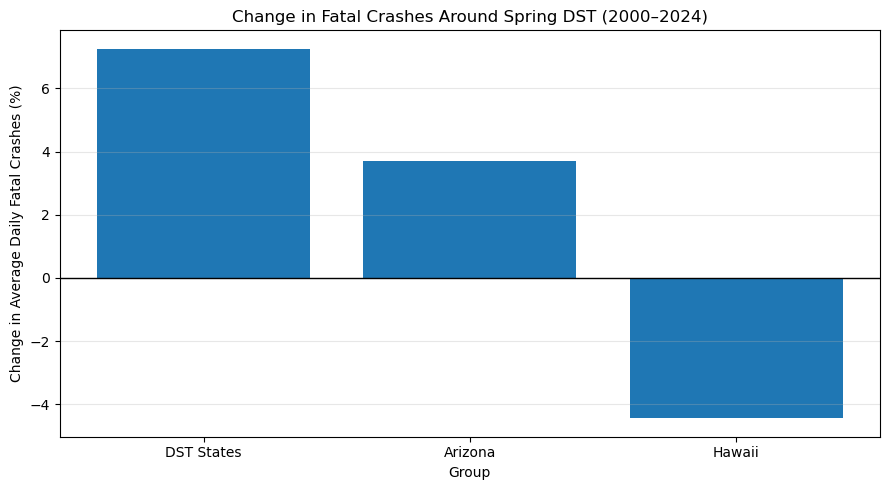

In [15]:

# Comparing the percentage changes across groups
comparison = pd.Series({
    "DST States": percent_change,
    "Arizona": control_summary.loc["Arizona", "Percent Change"],
    "Hawaii": control_summary.loc["Hawaii", "Percent Change"]
})

# Plotting the percentage changes
plt.figure(figsize=(9, 5))

plt.bar(
    comparison.index,
    comparison.values
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Change in Fatal Crashes Around Spring DST (2000–2024)")
plt.xlabel("Group")
plt.ylabel("Change in Average Daily Fatal Crashes (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### Preliminary Findings: Arizona and Hawaii Control Groups

Our control-group analysis examined fatal crash counts around the spring DST transition dates in Arizona and Hawaii, which generally do not observe DST.

We found that average daily fatal crashes increased by approximately 3.7% in Arizona and decreased by approximately 4.4% in Hawaii. In comparison, fatal crashes increased by 7.26% in DST-observing states.

These findings suggest that the increase observed in DST-observing states is not necessarily explained entirely by ordinary seasonal changes. However, Arizona's increase indicates that factors unrelated to the clock change may also influence crash frequencies.

The comparison remains descriptive. Differences in geography, weather, traffic volume, and population mean that these states are not perfectly comparable.

Further statistical modeling is required to determine whether the difference between DST-observing and non-DST states is statistically significant.



## Poisson Regression: Spring DST and Fatal Crashes

Our preliminary analysis found a 7.26% increase in fatal crashes during the six days following the spring DST transition. However, this comparison does not account for seasonal trends or other factors that may influence crash frequencies.

To investigate this further, we will use Poisson regression to model daily fatal crash counts.

The model will include:
- A variable indicating whether a day is before or after spring DST.
- Year, to account for differences in crash frequencies between years.
- Day of the week, to account for weekly traffic patterns.
- A time trend, to account for changes in crashes around the transition.

We will initially examine the 21 days before and after each spring DST transition, excluding the transition Sunday. We will later compare the results using shorter time windows.


In [16]:

# Counting fatal crashes for each date
daily_counts = (
    dst_crashes.groupby("crash_date")
    .size()
    .reset_index(name="fatal_crashes")
)

# Creating a calendar around each spring DST transition
calendar_dates = []

for _, row in dst_dates.iterrows():
    spring_date = pd.Timestamp(row["spring_dst"])

    dates = pd.date_range(
        start=spring_date - pd.Timedelta(days=21),
        end=spring_date + pd.Timedelta(days=21)
    )

    calendar_dates.extend(dates)

daily_crashes = pd.DataFrame({
    "crash_date": calendar_dates
})

# Adding daily crash counts
daily_crashes = daily_crashes.merge(
    daily_counts,
    on="crash_date",
    how="left"
)

# Including dates with zero recorded fatal crashes
daily_crashes["fatal_crashes"] = (
    daily_crashes["fatal_crashes"].fillna(0).astype(int)
)

# Adding the year and day of the week
daily_crashes["year"] = daily_crashes["crash_date"].dt.year
daily_crashes["day_of_week"] = daily_crashes["crash_date"].dt.dayofweek

# Adding spring DST dates
daily_crashes = daily_crashes.merge(
    dst_dates[["year", "spring_dst"]],
    on="year",
    how="left"
)

daily_crashes["spring_dst"] = pd.to_datetime(
    daily_crashes["spring_dst"]
)

# Calculating days relative to spring DST
daily_crashes["days_from_spring"] = (
    daily_crashes["crash_date"] - daily_crashes["spring_dst"]
).dt.days

# Excluding the transition Sunday
daily_crashes = daily_crashes[
    daily_crashes["days_from_spring"] != 0
].copy()

# Indicating whether the date is after DST
daily_crashes["post_dst"] = (
    daily_crashes["days_from_spring"] > 0
).astype(int)

# Checking the dataset
display(daily_crashes.head())

print("Daily observations:", len(daily_crashes))
print("Years covered:", daily_crashes["year"].nunique())
print("Missing crash counts:", daily_crashes["fatal_crashes"].isna().sum())


,crash_date,fatal_crashes,year,day_of_week,spring_dst,days_from_spring,post_dst
0,2000-03-12,92,2000,6,2000-04-02,-21,0
1,2000-03-13,84,2000,0,2000-04-02,-20,0
2,2000-03-14,76,2000,1,2000-04-02,-19,0
3,2000-03-15,75,2000,2,2000-04-02,-18,0
4,2000-03-16,69,2000,3,2000-04-02,-17,0


Daily observations: 1050
Years covered: 25
Missing crash counts: 0



### Poisson Regression Model

We will fit a Poisson regression model using daily fatal crash counts as the dependent variable.

Our explanatory variables are:

- `post_dst`: Whether the date is after the spring DST transition.
- `year`: Accounts for differences in fatal crashes between years.
- `day_of_week`: Accounts for weekly traffic patterns.
- `days_from_spring`: Accounts for a linear trend in crash counts around the transition.

We use standard errors clustered by year to account for possible dependence between daily observations within the same year.

The main variable of interest is `post_dst`. We will convert its coefficient into a percentage change to interpret the estimated association.


In [17]:

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Fitting the Poisson regression
poisson_model = smf.glm(
    formula="fatal_crashes ~ post_dst + C(year) + C(day_of_week) + days_from_spring",
    data=daily_crashes,
    family=sm.families.Poisson()
).fit(
    cov_type="cluster",
    cov_kwds={"groups": daily_crashes["year"]}
)

# Displaying the regression results
print(poisson_model.summary())

# Calculating the estimated percentage change after DST
beta = poisson_model.params["post_dst"]
p_value = poisson_model.pvalues["post_dst"]

ci = poisson_model.conf_int().loc["post_dst"]

percent_effect = (np.exp(beta) - 1) * 100
ci_lower = (np.exp(ci.iloc[0]) - 1) * 100
ci_upper = (np.exp(ci.iloc[1]) - 1) * 100

print("\nSpring DST Regression Results")
print(f"Estimated change: {percent_effect:.2f}%")
print(f"95% confidence interval: ({ci_lower:.2f}%, {ci_upper:.2f}%)")
print(f"P-value: {p_value:.4f}")

# Checking for overdispersion
dispersion = poisson_model.pearson_chi2 / poisson_model.df_resid
print(f"Dispersion statistic: {dispersion:.2f}")


                 Generalized Linear Model Regression Results                  
Dep. Variable:          fatal_crashes   No. Observations:                 1050
Model:                            GLM   Df Residuals:                     1017
Model Family:                 Poisson   Df Model:                           32
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3991.2
Date:                Sat, 07 Nov 2026   Deviance:                       1444.5
Time:                        17:37:21   Pearson chi2:                 1.44e+03
No. Iterations:                     4   Pseudo R-squ. (CS):             0.9488
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               4.3362    


### Sensitivity Analysis: Different Time Windows

Our initial Poisson regression used 21 days before and after the spring DST transition.

We will now repeat the same model using 7-, 14-, and 21-day windows to examine whether the estimated association changes depending on the observation period.

We will compare the estimated percentage changes, 95% confidence intervals, and p-values across the three models.

The transition Sunday will remain excluded.


In [18]:

# Comparing different windows around spring DST
results = []

for window in [7, 14, 21]:

    # Selecting dates within the window
    window_data = daily_crashes[
        daily_crashes["days_from_spring"].between(-window, window)
    ].copy()

    # Fitting the same Poisson model
    model = smf.glm(
        formula="fatal_crashes ~ post_dst + C(year) + C(day_of_week) + days_from_spring",
        data=window_data,
        family=sm.families.Poisson()
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": window_data["year"]}
    )

    # Extracting the DST estimate
    beta = model.params["post_dst"]
    ci = model.conf_int().loc["post_dst"]

    # Converting coefficients to percentages
    results.append({
        "Window": f"{window} days",
        "Estimated Change (%)": (np.exp(beta) - 1) * 100,
        "CI Lower (%)": (np.exp(ci.iloc[0]) - 1) * 100,
        "CI Upper (%)": (np.exp(ci.iloc[1]) - 1) * 100,
        "P-value": model.pvalues["post_dst"]
    })

# Displaying the comparison
sensitivity_results = pd.DataFrame(results)

display(sensitivity_results.round(4))


,Window,Estimated Change (%),CI Lower (%),CI Upper (%),P-value
0,7 days,17.6764,5.5316,31.2188,0.0034
1,14 days,8.6596,3.9041,13.6327,0.0003
2,21 days,4.8085,1.8336,7.8703,0.0014



### Comparing Raw and Adjusted Results

Our Poisson regression estimates were positive and statistically significant for all three comparison windows. However, the estimated percentage increase decreased as the window expanded from 7 to 21 days.

To better understand these differences, we will compare the raw before-and-after percentage changes with the adjusted regression estimates.

This will help us assess how much the results depend on the regression model and its seasonal trend adjustment.


In [19]:

# Comparing raw and adjusted changes across windows
raw_results = []

for window in [7, 14, 21]:

    # Selecting crashes before and after DST
    window_data = daily_crashes[
        daily_crashes["days_from_spring"].between(-window, window)
    ].copy()

    # Calculating average daily crashes
    averages = window_data.groupby("post_dst")["fatal_crashes"].mean()

    before = averages[0]
    after = averages[1]

    # Calculating the raw percentage change
    raw_change = (after - before) / before * 100

    raw_results.append({
        "Window": f"{window} days",
        "Before": before,
        "After": after,
        "Raw Change (%)": raw_change
    })

# Combining raw and regression results
raw_summary = pd.DataFrame(raw_results)

comparison_results = raw_summary.merge(
    sensitivity_results[["Window", "Estimated Change (%)"]],
    on="Window"
)

display(comparison_results.round(2))


,Window,Before,After,Raw Change (%),Estimated Change (%)
0,7 days,81.30,85.94,5.71,17.68
1,14 days,81.09,84.55,4.26,8.66
2,21 days,80.56,84.50,4.89,4.81



### Checking the Effect of Seasonal Trend Adjustment

Our regression estimates were larger than the raw percentage changes, especially for shorter comparison windows.

To investigate this difference, we will compare two Poisson regression models.

The first model controls for year and day of the week. The second includes the same variables along with a linear trend in days relative to spring DST.

By comparing the estimated effects, we can see how much our results depend on the seasonal trend adjustment.


In [20]:

# Comparing models with and without a seasonal trend
model_comparison = []

for window in [7, 14, 21]:

    # Selecting dates within each window
    window_data = daily_crashes[
        daily_crashes["days_from_spring"].between(-window, window)
    ].copy()

    formulas = {
        "Without Trend": "fatal_crashes ~ post_dst + C(year) + C(day_of_week)",
        "With Trend": "fatal_crashes ~ post_dst + C(year) + C(day_of_week) + days_from_spring"
    }

    for model_name, formula in formulas.items():

        # Fitting the Poisson model
        model = smf.glm(
            formula=formula,
            data=window_data,
            family=sm.families.Poisson()
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": window_data["year"]}
        )

        # Extracting the DST estimate
        beta = model.params["post_dst"]
        ci = model.conf_int().loc["post_dst"]

        model_comparison.append({
            "Window": f"{window} days",
            "Model": model_name,
            "Change (%)": (np.exp(beta) - 1) * 100,
            "CI Lower (%)": (np.exp(ci.iloc[0]) - 1) * 100,
            "CI Upper (%)": (np.exp(ci.iloc[1]) - 1) * 100,
            "P-value": model.pvalues["post_dst"]
        })

# Displaying the comparison
model_comparison = pd.DataFrame(model_comparison)

display(model_comparison.round(3))


,Window,Model,Change (%),CI Lower (%),CI Upper (%),P-value
0,7 days,Without Trend,5.707,2.721,8.780,0.000
1,7 days,With Trend,17.676,5.532,31.219,0.003
2,14 days,Without Trend,4.260,1.610,6.978,0.001
3,14 days,With Trend,8.660,3.904,13.633,0.000
4,21 days,Without Trend,4.894,2.003,7.867,0.001
5,21 days,With Trend,4.808,1.834,7.870,0.001



### Poisson Regression with Different Trends Before and After DST

Our sensitivity analysis showed that estimates were strongly influenced by the linear seasonal trend adjustment, particularly for shorter comparison windows.

Our previous model assumed that expected crash counts followed the same time trend before and after DST.

We now include an interaction between the post-DST indicator and days relative to the transition. This allows the pre-DST and post-DST trends to have different slopes while estimating the change at the transition.

We use a 21-day window on each side of the spring DST transition.


In [21]:

# Selecting the 21-day window
trend_data = daily_crashes[
    daily_crashes["days_from_spring"].between(-21, 21)
].copy()

# Fitting a model with different pre- and post-DST slopes
interaction_model = smf.glm(
    formula="fatal_crashes ~ post_dst * days_from_spring + C(year) + C(day_of_week)",
    data=trend_data,
    family=sm.families.Poisson()
).fit(
    cov_type="cluster",
    cov_kwds={"groups": trend_data["year"]}
)

# Showing the coefficients related to DST
terms = ["post_dst", "days_from_spring",
         "post_dst:days_from_spring"]

display(interaction_model.summary2().tables[1].loc[terms].round(4))

# Interpreting the estimated jump at DST
beta = interaction_model.params["post_dst"]
ci = interaction_model.conf_int().loc["post_dst"]

print(f"Estimated change at DST: {(np.exp(beta) - 1) * 100:.2f}%")
print(f"95% CI: ({(np.exp(ci.iloc[0]) - 1) * 100:.2f}%, "
      f"{(np.exp(ci.iloc[1]) - 1) * 100:.2f}%)")
print(f"P-value: {interaction_model.pvalues['post_dst']:.4f}")


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
post_dst,0.0469,0.0146,3.2196,0.0013,0.0184,0.0755
days_from_spring,0.0016,0.0010,1.6460,0.0998,-0.0003,0.0035
post_dst:days_from_spring,-0.0030,0.0016,-1.8770,0.0605,-0.0062,0.0001


Estimated change at DST: 4.80%
95% CI: (1.85%, 7.84%)
P-value: 0.0013



## Poisson Regression: Spring DST and Traffic Fatalities

Our previous analysis modeled the number of fatal crashes per day. We now examine the total number of people killed in those crashes.

We use the FARS `fatals` variable, which records the number of fatalities associated with each crash. We aggregate these values by date and fit a Poisson regression using the same 21-day window, year effects, day-of-week effects, and linear time trend.

This allows us to compare whether the association between spring DST and traffic fatalities is similar to the association observed for fatal crash counts.


In [22]:


# Counting total fatalities for each date
fatality_counts = (
    dst_crashes.groupby("crash_date")["fatals"]
    .sum()
    .reset_index(name="fatalities")
)

# Adding fatalities to our existing daily dataset
daily_fatalities = daily_crashes.merge(
    fatality_counts,
    on="crash_date",
    how="left"
)

daily_fatalities["fatalities"] = (
    daily_fatalities["fatalities"].fillna(0)
)

# Selecting 21 days before and after spring DST
fatality_data = daily_fatalities[
    daily_fatalities["days_from_spring"].between(-21, 21)
].copy()

# Checking the average fatalities before and after DST
display(
    fatality_data.groupby("post_dst")["fatalities"]
    .agg(["mean", "sum", "count"])
    .round(2)
)





,mean,sum,count
post_dst,,,
0,88.69,46563,525
1,92.86,48751,525



### Model Diagnostics: Observed vs. Predicted Crash Counts

Before interpreting our final Poisson regression results, we examine how well the model fits the daily crash counts.

We compare the observed counts with the fitted values from our 21-day Poisson regression. We also calculate the Pearson dispersion statistic to assess whether the variability in the data exceeds what the Poisson model assumes.


Observed mean: 82.53
Predicted mean: 82.53
Pearson dispersion: 1.42


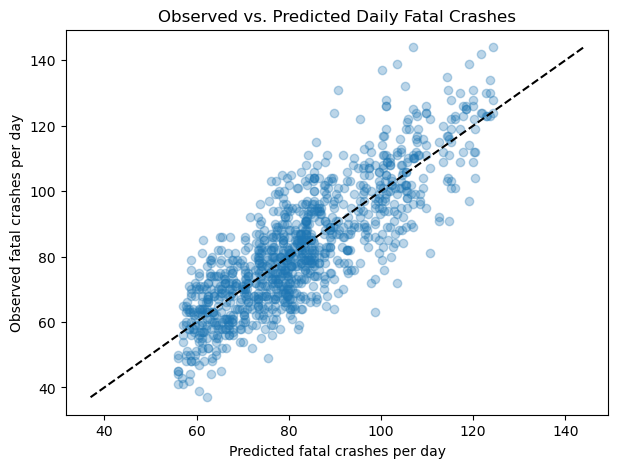

In [23]:

# Comparing observed and predicted fatal crash counts
diagnostics = daily_crashes[
    daily_crashes["days_from_spring"].between(-21, 21)
].copy()

diagnostics["predicted"] = poisson_model.predict(diagnostics)

# Comparing observed and predicted counts
print("Observed mean:", round(diagnostics["fatal_crashes"].mean(), 2))
print("Predicted mean:", round(diagnostics["predicted"].mean(), 2))

# Checking the Poisson variance assumption
dispersion = poisson_model.pearson_chi2 / poisson_model.df_resid
print("Pearson dispersion:", round(dispersion, 2))

# Plotting observed versus predicted counts
plt.figure(figsize=(7, 5))
plt.scatter(
    diagnostics["predicted"],
    diagnostics["fatal_crashes"],
    alpha=0.3
)

limits = [
    min(diagnostics["predicted"].min(), diagnostics["fatal_crashes"].min()),
    max(diagnostics["predicted"].max(), diagnostics["fatal_crashes"].max())
]

plt.plot(limits, limits, linestyle="--", color="black")
plt.xlabel("Predicted fatal crashes per day")
plt.ylabel("Observed fatal crashes per day")
plt.title("Observed vs. Predicted Daily Fatal Crashes")
plt.show()



### Simulating Daily Fatal Crash Counts

We simulate a new set of daily fatal crash counts using the fitted values from our Poisson regression.

For each day, we generate a random count from a Poisson distribution whose mean equals the model's predicted count.

This allows us to compare simulated outcomes with the actual observations and understand the variability assumed by the model. The simulated values are illustrative and do not replace the observed FARS data.


Observed mean: 82.53
Predicted mean: 82.53
Simulated mean: 82.51


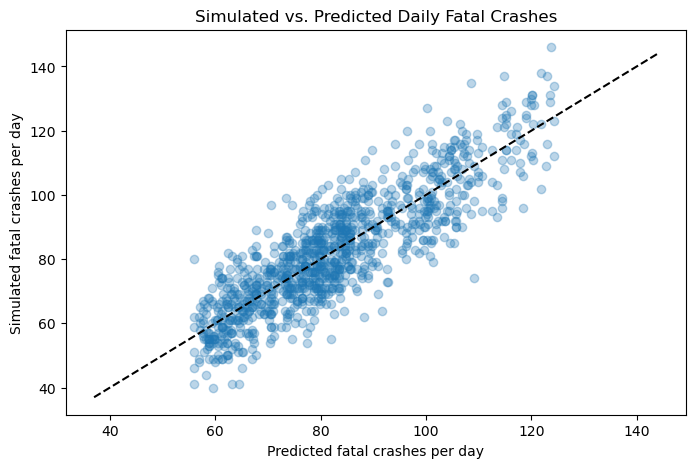

In [47]:

# Generating simulated crash counts from our Poisson model
rng = np.random.default_rng(44)

simulation = diagnostics.copy()

simulation["simulated_crashes"] = rng.poisson(
    lam=simulation["predicted"]
)

# Comparing averages
print("Observed mean:", round(simulation["fatal_crashes"].mean(), 2))
print("Predicted mean:", round(simulation["predicted"].mean(), 2))
print("Simulated mean:", round(simulation["simulated_crashes"].mean(), 2))

# Plotting observed and simulated counts
plt.figure(figsize=(8, 5))

plt.scatter(
    simulation["predicted"],
    simulation["simulated_crashes"],
    alpha=0.3
)

plt.plot(limits, limits, linestyle="--", color="black")
plt.xlabel("Predicted fatal crashes per day")
plt.ylabel("Simulated fatal crashes per day")
plt.title("Simulated vs. Predicted Daily Fatal Crashes")
plt.show()



### Checking Overdispersion Using Simulated Crash Counts

Our Poisson regression had a Pearson dispersion statistic of 1.42, indicating more variation in the observed crash counts than the model assumes.

We now compare the observed dispersion with dispersion values from 500 datasets simulated under the fitted Poisson model.

This helps us assess whether the observed variability is unusual under our assumed Poisson distribution.


Observed dispersion: 1.42
Average simulated dispersion: 1.00


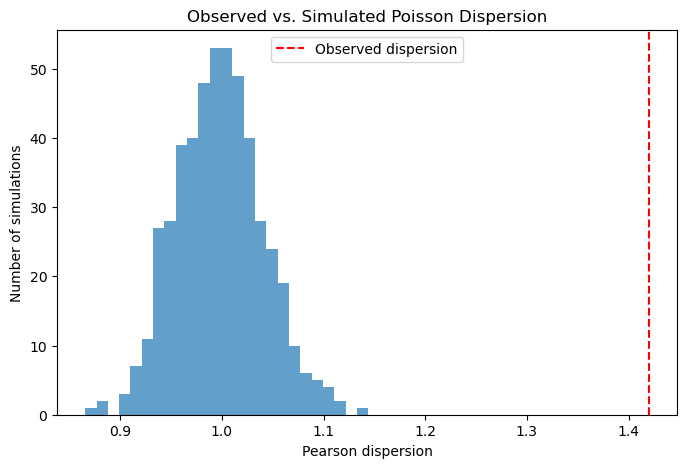

In [49]:

# Observed Pearson dispersion
observed_dispersion = poisson_model.pearson_chi2 / poisson_model.df_resid

# Simulating 500 datasets from the fitted Poisson model
rng = np.random.default_rng(42)
predicted = poisson_model.fittedvalues.to_numpy()

simulated_dispersions = []

for i in range(500):
    simulated_counts = rng.poisson(lam=predicted)

    # Pearson dispersion using the original fitted means
    pearson_stat = np.sum(
        (simulated_counts - predicted) ** 2 / predicted
    )

    simulated_dispersions.append(
        pearson_stat / len(predicted)
    )

# Comparing observed and simulated dispersion
print(f"Observed dispersion: {observed_dispersion:.2f}")
print(f"Average simulated dispersion: {np.mean(simulated_dispersions):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(simulated_dispersions, bins=25, alpha=0.7)
plt.axvline(observed_dispersion, color="red",
            linestyle="--", label="Observed dispersion")
plt.xlabel("Pearson dispersion")
plt.ylabel("Number of simulations")
plt.title("Observed vs. Simulated Poisson Dispersion")
plt.legend()
plt.show()



## Summary of Spring DST Statistical Findings

We summarize the main results from our analysis of fatal motor vehicle crashes around the spring DST transition.

Our analysis includes descriptive before-and-after comparisons, a paired t-test, Poisson regression with year, weekday, and seasonal-trend adjustments, and sensitivity checks using different comparison windows.

The regression results consistently indicated a positive association between the spring DST transition and fatal crash frequency. However, the estimated magnitude depended on the observation window and trend specification.

Model diagnostics also indicated overdispersion, suggesting that the basic Poisson variance assumption does not fully capture the variability in daily crash counts.


In [50]:

# Summarizing the main spring DST regression results
final_summary = pd.DataFrame({
    "Analysis": [
        "Raw comparison (21 days)",
        "Poisson without trend (21 days)",
        "Poisson with linear trend (21 days)",
        "Poisson with separate slopes (21 days)"
    ],
    "Estimated Change (%)": [
        4.89,
        4.894,
        4.8085,
        4.80
    ]
})

display(final_summary.round(2))

# Displaying the final model diagnostics
print(f"\nPearson dispersion: {dispersion:.2f}")
print("Standard errors: Clustered by year")
print("Observation window: 21 days before and after spring DST")
print("Transition day: Excluded")
print("Years included: 2000–2024")


,Analysis,Estimated Change (%)
0,Raw comparison (21 days),4.89
1,Poisson without trend (21 days),4.89
2,Poisson with linear trend (21 days),4.81
3,Poisson with separate slopes (21 days),4.80



Pearson dispersion: 1.42
Standard errors: Clustered by year
Observation window: 21 days before and after spring DST
Transition day: Excluded
Years included: 2000–2024


In [51]:

# Collecting results directly from our fitted models
raw_before = diagnostics.loc[
    diagnostics["post_dst"] == 0, "fatal_crashes"
].mean()

raw_after = diagnostics.loc[
    diagnostics["post_dst"] == 1, "fatal_crashes"
].mean()

raw_change = (raw_after / raw_before - 1) * 100

# Using the previously fitted regression models
summary_values = {
    "Raw comparison (21 days)": raw_change,
    "Poisson without trend (21 days)": model_comparison.loc[
        (model_comparison["Window"] == "21 days") &
        (model_comparison["Model"] == "Without Trend"),
        "Change (%)"
    ].iloc[0],
    "Poisson with linear trend (21 days)": (
        np.exp(poisson_model.params["post_dst"]) - 1
    ) * 100,
    "Poisson with separate slopes (21 days)": (
        np.exp(interaction_model.params["post_dst"]) - 1
    ) * 100
}

final_summary = pd.DataFrame(
    list(summary_values.items()),
    columns=["Analysis", "Estimated Change (%)"]
)

display(final_summary.round(2))


,Analysis,Estimated Change (%)
0,Raw comparison (21 days),4.89
1,Poisson without trend (21 days),4.89
2,Poisson with linear trend (21 days),4.81
3,Poisson with separate slopes (21 days),4.80
